In [1]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR-RECAP/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import myplot
import numpy.ma as ma
from myplot import *
import obsinfo as obs
from obsinfo import *
from pyproj import Transformer

In [2]:
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/stations_central_asia/'
fileCentralAsia='Taver_v1_1.txt'

In [3]:
df_all_stations = pd.read_csv(sourceData+fileCentralAsia, sep="\t") 
df_all_stations[0:5]

,Country,Code,Name,Long,Lat,Alt,Years,I,II,III,IV,V,VI,VII,VIII,IX,X,XI,XII
0,211,36870.0,Almaty,76.93,43.23,847,1879,-9.8,-6.1,4.5,12.4,18.8,24.3,24.6,21.2,14.5,7.5,-1.5,-4.1
1,211,36870.0,Almaty,76.93,43.23,847,1880,-10.2,-10.9,2.0,7.0,15.8,21.3,22.3,20.1,14.0,10.6,1.5,-6.7
2,211,36870.0,Almaty,76.93,43.23,847,1881,-4.8,6.0,1.1,13.8,16.3,18.6,22.7,21.1,14.9,6.4,-2.0,-11.4
3,211,36870.0,Almaty,76.93,43.23,847,1882,-8.4,-8.9,-2.1,9.7,16.2,20.0,21.5,20.4,15.3,3.2,-1.1,-7.7
4,211,36870.0,Almaty,76.93,43.23,847,1883,-10.7,-14.0,2.8,7.9,16.3,21.3,21.8,21.6,14.3,6.7,-3.4,-6.0


In [4]:
station_check = df_all_stations.groupby('Code')['Name'].nunique()
station_check[0:5]

Series([], Name: Name, dtype: int64)

In [5]:
duplicates = station_check[station_check > 1]
print(duplicates)

Code
38350.0    2
38354.0    2
38745.0    2
38838.0    2
38844.0    2
38943.0    2
38956.0    2
Name: Name, dtype: int64


In [6]:
print(df_all_stations[df_all_stations['Code'] == 35796][['Code','Name', 'Long', 'Lat', 'Alt']].drop_duplicates()
)

        Code     Name   Long   Lat  Alt
224  35796.0  Balhash  75.08  46.8  350


In [7]:
###There are some WMO code with two different names, need to check is it is just a name change or an errror?
##For the moment I remove them

In [8]:
# First, ensure Code_WMO is numeric and drop NaNs for analysis
df_valid_codes = df_all_stations[df_all_stations['Code'].notna()].copy()

# Remove the duplicates (as before)
station_check = df_valid_codes.groupby('Code')['Name'].nunique()
duplicates = station_check[station_check > 1].index.tolist()

# Remove all rows with these duplicated WMO codes
df_clean = df_all_stations[~df_all_stations['Code'].isin(duplicates)].copy()

# Final check
print("Original rows:", len(df_all_stations))
print("Rows after removing duplicates:",len(df_clean))


Original rows: 12019
Rows after removing duplicates: 11413


In [9]:
## Model MAR
domain='GRp'
sourceDataGrid='/home/santolam/'
fileName_grF='NST.2014.01.01.00.GRi.nc'
#fileName_grM='NST.2000.01.01.00.GRa_Mera.nc_ICEmask'
dsF= xr.open_dataset(sourceDataGrid+fileName_grF) ## Year mean?
print('lon min',dsF.LON.values.min(),'lon max',dsF.LON.values.max())
print('lat min',dsF.LAT.values.min(),'lat max',dsF.LAT.values.max())

lon_min, lon_max =dsF.LON.values.min(),dsF.LON.values.max()
lat_min, lat_max= dsF.LAT.values.min(),dsF.LAT.values.max()
print(lon_min,lon_max)
print(lat_min,lat_max)

lon min 6.7526566e+01 lon max 77.156975
lat min 36.19467 lat max 41.38051
67.526566 77.156975
36.19467 41.38051


In [10]:
df_dom= df_clean[
    (df_clean['Long'] >= lon_min) & (df_clean['Long'] <= lon_max) &
    (df_clean['Lat'] >= lat_min) & (df_clean['Lat'] <= lat_max)
]

In [11]:
df_dom[0:5]

,Country,Code,Name,Long,Lat,Alt,Years,I,II,III,IV,V,VI,VII,VIII,IX,X,XI,XII
2491,213,38623.0,Arpa,74.9,40.8,3000,1961,-24.0,-24.0,-15.6,1.2,6.5,8.0,11.3,9.9,6.0,-4.7,-12.3,-20.1
2492,213,38623.0,Arpa,74.9,40.8,3000,1962,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0,-999.0
2493,213,38623.0,Arpa,74.9,40.8,3000,1963,-26.2,-20.6,-12.5,0.9,6.0,8.5,9.9,9.4,4.2,-0.8,-13.5,-18.8
2494,213,38623.0,Arpa,74.9,40.8,3000,1964,-27.6,-19.8,-10.8,0.0,3.0,6.8,9.4,9.8,4.2,-5.2,-11.2,-20.1
2495,213,38623.0,Arpa,74.9,40.8,3000,1965,-20.1,-21.6,-13.0,0.9,5.2,7.4,10.5,8.7,4.2,-0.7,-17.1,-26.4


In [12]:
# Replace -999.0 (missing value) with NaN
df = df_dom.replace(-999.0, np.nan)

# List of month column names
month_cols = ['I', 'II', 'III', 'IV', 'V', 'VI', 'VII', 'VIII', 'IX', 'X', 'XI', 'XII']

df[month_cols] = df[month_cols].apply(pd.to_numeric, errors='coerce') #if not I have an error, they are strings
df.replace(-999.0, np.nan, inplace=True)


df['DJF'] = (df['XII'].shift(1) + df['I'] + df['II']) / 3 # DJF: Dec (from previous year), Jan, Feb
df['MAM'] = (df['III'] + df['IV'] + df['V']) / 3
df['JJA'] = (df['VI'] + df['VII'] + df['VIII']) / 3
df['SON'] = (df['IX'] + df['X'] + df['XI']) / 3
df['Annual'] = df[month_cols].mean(axis=1, skipna=True)

# Now include it in your seasonal_means DataFrame
seasonal_means = df[['Code', 'Name', 'Long', 'Lat', 'Alt', 'Years', 
                     'DJF', 'MAM', 'JJA', 'SON', 'Annual']]
#stations_list=[]
grouped = seasonal_means.groupby('Code')

stations_dict = {}
for wmo_code, group in grouped:
    group = group.reset_index(drop=True)
    #stations_list.append(group)  # for iteration
    stations_dict[wmo_code] = group.set_index('Years')  # for direct lookup and time series


In [13]:
ann_clim = (
    seasonal_means
    .groupby(['Code', 'Name', 'Long', 'Lat', 'Alt'], as_index=False)
    .agg(
        iyear=('Years', 'min'),
        fyear=('Years', 'max'),
        ann_mean=('Annual', 'mean')
    )
)

In [14]:
#station_info['Long'].values

In [15]:

lat_stas =ann_clim['Lat'].values   #extract_column_float(data_dicts, 'Lat')
lon_stas = ann_clim['Long'].values 
elev_stas= ann_clim['Alt'].values 
codes =ann_clim['Code'].values

lon_MAR=dsF.LON;lat_MAR=dsF.LAT
iMAR_sta=[];jMAR_sta=[] ##coord of MAR pixel corresponding to station location

for pos in np.arange(len(lat_stas)):
    target_lon,target_lat=float(lon_stas[pos]),float(lat_stas[pos])
    # Compute distance to each grid point
    dist = np.sqrt((lon_MAR - target_lon)**2 + (lat_MAR - target_lat)**2)
    j, i = np.unravel_index(dist.argmin(), dist.shape) 
    jMAR_sta.append(j);iMAR_sta.append(i)

In [16]:
##Comparison of elevation (for example) at one point
SH_MAR_sta=dsF.SH[jMAR_sta[0],iMAR_sta[0]]
dif=elev_stas[0]-SH_MAR_sta.values
print(dif)

-627.819091796875


In [17]:

##For all points
SHList_dom=[];LONList_dom=[];LATList_dom=[]
for k in range(len(jMAR_sta)):
    tmp=dsF.SH[jMAR_sta[k],iMAR_sta[k]]
    SHList_dom.append(tmp)
    tmp1=dsF.LON[jMAR_sta[k],iMAR_sta[k]]
    LONList_dom.append(tmp1)
    tmp2=dsF.LAT[jMAR_sta[k],iMAR_sta[k]]
    LATList_dom.append(tmp2)


In [18]:
ds_stations_MARgrid= [{
    'codes_wmo':int(codes[i]),
    'lat_sta_ori': lat_stas[i],
    'lon_sta_ori':lon_stas[i],
    'elev_station_ori': elev_stas[i],
    'pix_i_sta_mar':iMAR_sta[i], ## coord i,j: Position of station in the pixel of MAR grid (the closest)
    'pix_j_sta_mar':jMAR_sta[i], ## coord i,j: Position of station in the pixel of MAR grid (the closest)
    'elev_MAR_pix': SHList_dom[i].values,
    'lat_mar':LATList_dom[i].values, #Same as pix i,j to test that it it the same point
    'lon_mar':LONList_dom[i].values
} for i in range(len(SHList_dom))]


df_stations_MARgrid= pd.DataFrame(ds_stations_MARgrid)


In [19]:
##PRECIP comparison

In [ ]:
domainM='GRp';
ds_TTZ_raw=xr.open_mfdataset('/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/GRp/spin2/work/monthly/'+
    'TTZ_monmean_MARv3.14_ER5_spin2_GRp_*.nc')['TTZ'].sel(ZTQLEV=2)
ds_TTZ= ds_TTZ_raw.rename({'TIME': 'time'})
ds_TTZ=ds_TTZ#[:,ny:-ny,nx:-nx]
fyr=1990

#ds_TTZ=ds_TTZ.sel(time=slice("1950",fyr))
ds_TTZ = ds_TTZ.sel(time=slice("1950-01-01", f"{fyr}-12-31"))
dsSH=dsF.SH

In [ ]:
from scipy import stats

def monthly_lapse_rate(ds_TTZ, dsSH):
    """
    Compute lapse rate (°C/km) for monthly temperature data.

    Parameters
    ----------
    ds_TTZ : xarray.DataArray
        Temperature data (monthly) [time, lat, lon]
    dsSH : xarray.DataArray
        Surface height (elevation) [lat, lon]

    Returns
    -------
    xarray.DataArray
        Monthly lapse rate in °C/km
    """
    lapse_rates = []
    for t in ds_TTZ.time:
        T = ds_TTZ.sel(time=t).values.flatten()
        Z = dsSH.values.flatten()
        mask = np.isfinite(T) & np.isfinite(Z)

        slope, _, _, _, _ = stats.linregress(Z[mask], T[mask])
        lapse_rates.append(slope * 1000)  # °C/km

    return xr.DataArray(
        lapse_rates,
        coords=[ds_TTZ.time],
        dims=["time"],
        name="lapse_rate"
    )

# Example usage:
lr_monthly = monthly_lapse_rate(ds_TTZ, dsSH)
print(lr_monthly.shape)


In [ ]:
#vals,anoms=climb.seasonal_selection(ds_TF,'DJF',1980,2024)

vals,anoms=climb.seasonal_selection(ds_TTZ,'JFMAMJJASOND',1950,fyr)
#vals.time
lr_annual = lr_monthly.groupby('time.year').mean('time')
ts_mar = vals.isel(Y=j, X=i)

In [ ]:

mar_rows = []

for _, row in df_stations_MARgrid.iterrows():
    code = int(row.codes_wmo)
    i = int(row.pix_i_sta_mar)
    j = int(row.pix_j_sta_mar)
    
    # Extract MAR monthly time series for this station
    ts_mar = ds_TTZ.isel(Y=j, X=i)  # adjust dimension names if needed

    # Elevation difference in km
    dz = (row.elev_station_ori - row.elev_MAR_pix) / 1000

    # Apply lapse-rate correction: T_corr = T_MAR + Gamma * dz
    ts_mar_corr = ts_mar + lr_monthly * dz
    
    # Save as DataFrame
    mar_df = pd.DataFrame({
        'Code_WMO': code,
        'Time': ts_mar.time.values,
        'MAR_Original': ts_mar.values,
        'MAR_Corrected': ts_mar_corr.values
    })

    mar_rows.append(mar_df)

df_mar_monthly = pd.concat(mar_rows, ignore_index=True)


In [ ]:
#df_mar_monthly

In [ ]:
#df_stations_MARgrid

In [ ]:
rows = []

for _, row in df_stations_MARgrid.iterrows():
    code = int(row.codes_wmo)
    sta = stations_dict[code]
    sta_years = sta.index.astype(int)
    sta_ann = sta['Annual']
    
    ts_mar = ds_TTZ.isel(Y=row.pix_j_sta_mar, X=row.pix_i_sta_mar)

    dz = (row.elev_station_ori - row.elev_MAR_pix) / 1000

    # --- compute overlapping period
    iyear = max(sta_years.min(), lr_annual.year.min().item())
    fyear = min(sta_years.max(), lr_annual.year.max().item())

    if iyear > fyear:
        continue

    # --- overlapping station annual series
    sta_c = sta_ann.loc[iyear:fyear]

    # --- select MAR annual mean for overlapping period
    mar_c = ts_mar.sel(time=slice(f'{iyear}-01-01', f'{fyear}-12-31'))
    mar_c_ann = mar_c.groupby('time.year').mean('time')
    
    # --- select lapse rate for overlapping years
    lr_c = lr_annual.sel(year=slice(iyear, fyear))

    # --- apply lapse-rate correction year by year
    ts_mar_corr_ann = mar_c_ann + lr_c * dz

    # --- climatological means
    ann_mean_mar = mar_c_ann.mean().compute().item();
    ann_mean_mar_corr = ts_mar_corr_ann.mean().compute().item();

    ann_mean_obs = float(sta_c.mean())

    rows.append({
        'Code_WMO': code,
        'iyear': iyear,
        'fyear': fyear,
        'ann_mean_obs': ann_mean_obs,
        'ann_mean_MAR': ann_mean_mar,
        'ann_mean_MAR_corr': ann_mean_mar_corr,
        'bias_MAR-sta': ann_mean_mar - ann_mean_obs,
        'bias_MAR-sta_corr': ann_mean_mar_corr - ann_mean_obs,
        'elev_sta': row.elev_station_ori,
        'elev_MAR_pix': row.elev_MAR_pix
    })

df_clim_MAR = pd.DataFrame(rows)


In [ ]:
df_clim_MAR

In [ ]:

# Compute the overlapping period
df_clim_MAR['period'] = df_clim_MAR['fyear'] - df_clim_MAR['iyear'] + 1


In [ ]:
records = []

for _, row in df_stations_MARgrid.iterrows():
    wmo = int(row["codes_wmo"])
    iy  = int(row["pix_j_sta_mar"])
    ix  = int(row["pix_i_sta_mar"])

    # Extract MAR monthly series at that grid point
    da_sta = ds_TTZ.isel(Y=iy, X=ix).rename("TTZ")  # give it a name

    # Elevation difference in km
    dz = (row.elev_station_ori - row.elev_MAR_pix) / 1000

    # Apply lapse-rate correction per month
    da_sta_corr = (da_sta + lr_monthly * dz).rename("TTZ_corr")  # name is required

    # Convert corrected series to DataFrame
    df = da_sta_corr.to_dataframe().reset_index()

    # Add metadata
    df["Code_WMO"] = wmo
    df["Lat"]      = row["lat_mar"]
    df["Long"]     = row["lon_mar"]
    df["Alt"]      = row["elev_MAR_pix"]

    records.append(df)

df_model_long = pd.concat(records, ignore_index=True)
df_model_long["Years"] = df_model_long["time"].dt.year
df_model_long["Month"] = df_model_long["time"].dt.month


In [ ]:
df_model_long

In [ ]:
df_model_wide = (
    df_model_long
    .pivot_table(
        index=["Code_WMO", "Lat", "Long", "Alt", "Years"],
        columns="Month",
        values="TTZ_corr",
        aggfunc="mean"   # monthly mean or sum, adjust if needed
    )
    .reset_index()
)

In [ ]:
#df_model_wide

In [ ]:
month_map = {
    1: "I", 2: "II", 3: "III", 4: "IV",
    5: "V", 6: "VI", 7: "VII", 8: "VIII",
    9: "IX", 10: "X", 11: "XI", 12: "XII"
}

df_model_wide = df_model_wide.rename(columns=month_map)


In [ ]:
df_model_wide["Country"] = None
df_model_wide["Name"]    = "MAR_grid"

cols = [
    "Country", "Code_WMO", "Name",
    "Long", "Lat", "Alt", "Years",
    "I", "II", "III", "IV", "V", "VI",
    "VII", "VIII", "IX", "X", "XI", "XII"
]

df_model_final = df_model_wide[cols]


In [ ]:
#df_model_final

In [ ]:
#df_dom[0:3]

In [ ]:
wmo  = 38586
year = 1984

obs = (
    df_dom
    .query("Code == @wmo and Years == @year")
    .iloc[0]
)


mar = (
    df_model_final
    .query("Code_WMO == @wmo and Years == @year")
    .iloc[0]
)


months = ["I","II","III","IV","V","VI","VII","VIII","IX","X","XI","XII"]

df_compare = pd.DataFrame({
    "Month": months,
    "OBS": obs[months].astype(float).values,
    "MAR": mar[months].astype(float).values,
})

df_compare["Bias"] = df_compare["MAR"] - df_compare["OBS"]
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
plt.plot(months, df_compare["OBS"], marker="o", color='blue',label="OBS")
plt.plot(months, df_compare["MAR"], marker="o",color='orange', label="MAR")

plt.title(f"WMO {wmo} – {year}")
plt.ylabel("Monthly precipitation (mm)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



In [ ]:
df_dom_clean = df_dom.copy()
#df_dom_clean[months] = df_dom_clean[months].replace(-999.0, np.nan)
df_dom_clean[months] = df_dom_clean[months].apply(pd.to_numeric, errors="coerce")
df_dom_clean[months] = df_dom_clean[months].replace(-999.0, np.nan)


In [ ]:
def monthly_bias_common_period(df_obs, df_mar, wmo):
    """
    Returns a DataFrame with monthly climatological bias (MAR - OBS)
    computed over the common years only, with the number of years.
    """

    obs = df_obs[df_obs["Code"] == wmo]
    mar = df_mar[df_mar["Code_WMO"] == wmo]

    # Common years
    common_years = np.intersect1d(obs["Years"], mar["Years"])
    
    n_years = len(common_years)  # number of years used for climatology

    if n_years == 0:
        return None

    obs_c = obs[obs["Years"].isin(common_years)]
    mar_c = mar[mar["Years"].isin(common_years)]
    alt = obs_c["Alt"].iloc[0] if "Alt" in obs_c.columns else mar_c["Alt"].iloc[0]

    data = []

    for m in months:
        obs_mean = pd.to_numeric(obs_c[m], errors="coerce").mean()
        mar_mean = pd.to_numeric(mar_c[m], errors="coerce").mean()

        data.append({
            "Code_WMO": wmo,
            "Month": m,
            "OBS": obs_mean,
            "MAR": mar_mean,
            "Bias": mar_mean - obs_mean,
            "N_years": n_years,
            # same for all months
            "Alt": alt ,
            "common_years":common_years  
        })

    return pd.DataFrame(data)


In [ ]:
bias_list = []

common_stations = set(df_dom_clean["Code"]).intersection(
    set(df_model_final["Code_WMO"])
)

for wmo in common_stations:
    df_b = monthly_bias_common_period(df_dom_clean, df_model_final, wmo)
    if df_b is not None:
        bias_list.append(df_b)

df_bias_monthly = pd.concat(bias_list, ignore_index=True)


In [ ]:
np.max(df_bias_monthly.N_years.values)

In [ ]:
df_bias_monthly[0:4]

In [43]:
months = ["I","II","III","IV","V","VI","VII","VIII","IX","X","XI","XII"]

# Pivot bias to station x month
bias_mat = (
    df_bias_monthly
    .pivot(index="Code_WMO", columns="Month", values="Bias")
    .reindex(columns=months)
)

# Get station metadata: Altitude and number of years
station_meta = (
    df_bias_monthly
    .drop_duplicates("Code_WMO")
    .set_index("Code_WMO")[["Alt", "N_years","common_years"]]
)

# Order stations by elevation (low -> high)
station_order = station_meta["Alt"].sort_values().index
bias_mat = bias_mat.loc[station_order]
station_meta = station_meta.loc[station_order]

# y-axis labels: WMO (alt m)
#ylabels = [
 #   f"{int(wmo)} ({int(alt)} m)"
 #   for wmo, alt in zip(station_meta.index, station_meta["Alt"])
#]

ylabels = [
    f" {int(alt)}"
    for alt in station_meta["Alt"]
#
]


# Right y-axis values: number of years
n_years = station_meta["N_years"].values
#iyr="common_years":common_years,

In [44]:
#station_meta["common_years"]

In [45]:
station_meta["year_start"] = station_meta["common_years"].apply(lambda x: x[0] if len(x) > 0 else np.nan)
station_meta["year_end"]   = station_meta["common_years"].apply(lambda x: x[-1] if len(x) > 0 else np.nan)

# Check result
#station_meta[["year_start", "year_end"]].head()

Saved: /home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/figures_paper_on_evaluation/FIG11a_elevation_annual_cycle_bias_central_asia_Tavg.GRp_SH_ICE_pamir_rev1_Fanny1990.png


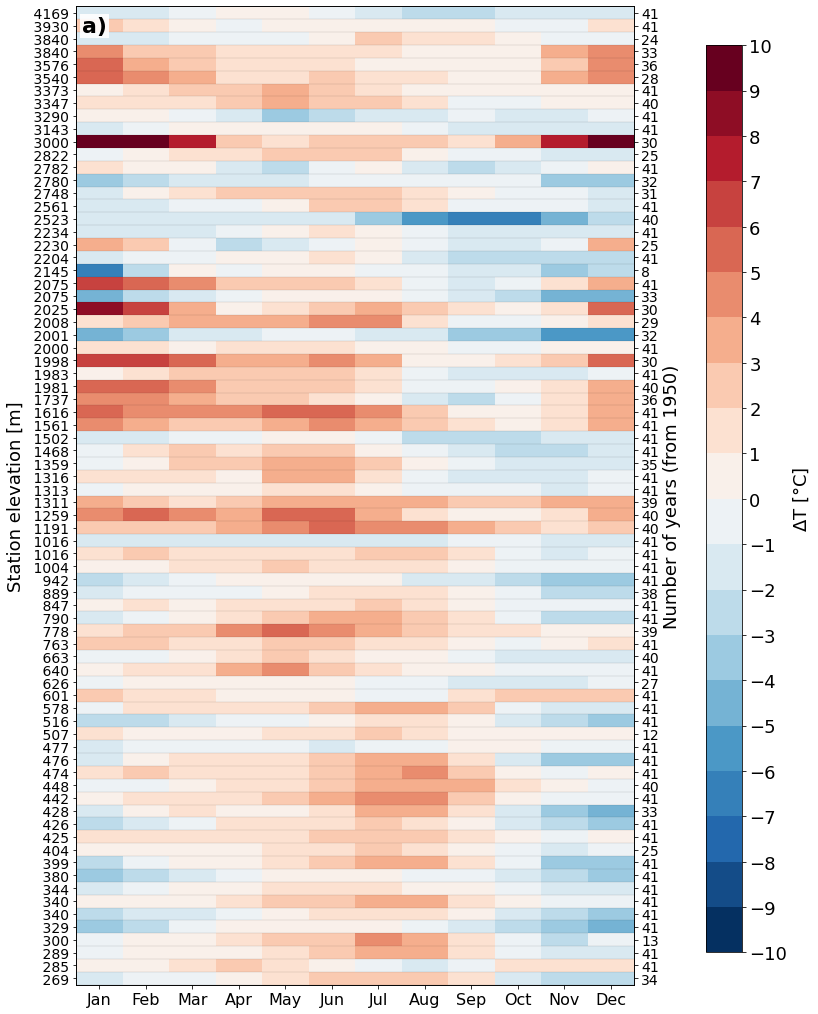

In [46]:

#months = ["I","II","III","IV","V","VI","VII","VIII","IX","X","XI","XII"]
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

Z = bias_mat.values #(station × month)
# ylabels = ["WMO (alt m)", ...]
# n_years = array/list of number of years for each station, same order as ylabels

# Define discrete intervals for the bias (mm)
bounds = np.arange(-10, 11, 1)  # adjust according to your data
cmap = plt.get_cmap("RdBu_r", len(bounds)-1)  # discrete BrBG
norm = mcolors.BoundaryNorm(bounds, cmap.N)

# Grid for pcolormesh
x = np.arange(len(months) + 1)
y = np.arange(len(ylabels) + 1)

fig, ax = plt.subplots(figsize=(10, 18))

# Plot bias
pcm = ax.pcolormesh(
    x, y, Z,
    cmap=cmap,
    norm=norm,
    shading="auto"
)

# Horizontal lines for each station
for yy in range(len(ylabels)):
    ax.axhline(yy, color="k", lw=0.3, alpha=0.3)

# Left y-axis: WMO + elevation
ax.set_yticks(np.arange(len(ylabels)) + 0.5)
ax.set_yticklabels(ylabels)
ax.set_ylabel("Station elevation [m]", fontsize=18)

# Right y-axis: number of years
ax2 = ax.twinx()
ax2.set_ylim(ax.get_ylim())  # align with left y-axis
ax2.set_yticks(np.arange(len(ylabels)) + 0.5)
ax2.set_yticklabels(n_years)  # n_years in same order as ylabels
ax2.set_ylabel("Number of years (from 1950)", fontsize=18)

# X-axis
ax.set_xticks(np.arange(len(months)) + 0.5)
ax.set_xticklabels(months)
#ax.set_xlabel("Month", fontsize=18)

ax.tick_params(axis="x", labelsize=16)
ax.tick_params(axis="y", labelsize=14)
ax2.tick_params(axis="y", labelsize=14)
#ax2.tick_params(axis="y", labelsize=16)

cbar_ax = fig.add_axes([1., 0.15, 0.05, 0.7])  # [left, bottom, width, height] in figure coords
cbar = fig.colorbar(pcm, cax=cbar_ax, orientation='vertical', ticks=bounds)
cbar.set_label("$\Delta$T [°C]", fontsize=18)
cbar.ax.tick_params(labelsize=18)

ax.text(
    0.01, 0.99,            # position relative à l'axe
    'a)',
    transform=ax.transAxes,
    fontsize=22,
    fontweight='bold',
    va='top',
    ha='left',
    bbox=dict(facecolor='white', edgecolor='none', alpha=0.9, pad=2)
)

plt.rcParams.update({
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16
})

#plt.tight_layout()
#plotsDir = "/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
plotsDir='/home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/figures_paper_on_evaluation/'
plotname = f"FIG11a_elevation_annual_cycle_bias_central_asia_Tavg.{domain}_SH_ICE_pamir_rev1_Fanny{fyr}"

plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
print(f"Saved: {plotsDir}{plotname}.png")

plt.show()



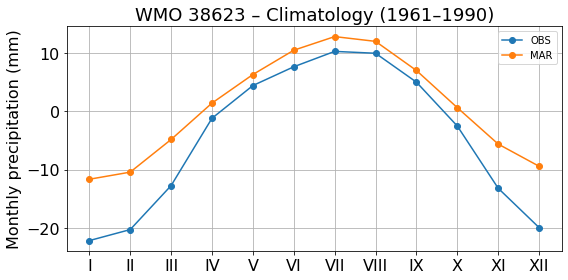

In [47]:
wmo = 38623
months = ["I","II","III","IV","V","VI","VII","VIII","IX","X","XI","XII"]

# Select station
obs_sta = df_dom_clean.query("Code == @wmo")
mar_sta = df_model_final.query("Code_WMO == @wmo")

# ---- Common period ----
start_year = max(obs_sta["Years"].min(), mar_sta["Years"].min())
end_year   = min(obs_sta["Years"].max(), mar_sta["Years"].max())

obs_sta_cp = obs_sta.query("@start_year <= Years <= @end_year")
mar_sta_cp = mar_sta.query("@start_year <= Years <= @end_year")

# ---- Monthly climatology over common period ----
obs_mean = obs_sta_cp[months].astype(float).mean(axis=0)
mar_mean = mar_sta_cp[months].astype(float).mean(axis=0)

df_compare = pd.DataFrame({
    "Month": months,
    "OBS": obs_mean.values,
    "MAR": mar_mean.values
})
df_compare["Bias"] = df_compare["MAR"] - df_compare["OBS"]

# ---- Plot ----
plt.figure(figsize=(8,4))
plt.plot(months, df_compare["OBS"], marker="o", label="OBS")
plt.plot(months, df_compare["MAR"], marker="o", label="MAR")

plt.title(f"WMO {wmo} – Climatology ({start_year}–{end_year})")
plt.ylabel("Monthly precipitation (mm)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
